In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully")

All libraries imported successfully


In [ ]:
orders = pd.read_csv('/content/orders.csv')
products = pd.read_csv('/content/products (1).csv')
customers = pd.read_csv('/content/customers (2).csv')

print("Orders Dataset:", orders.shape)
print("Products Dataset:", products.shape)
print("Customers Dataset:", customers.shape)

Orders Dataset: (25000, 13)
Products Dataset: (180, 8)
Customers Dataset: (5000, 6)


In [ ]:
display(orders.head())
display(products.head())
display(customers.head())

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount_Percent,Discount_Amount,Sales,Profit,Payment_Mode,Order_Status,Return_Status
0,ORD000001,2023-08-19,CUST00482,PRD0170,1,2999,25.0,749.75,2249.25,973.25,Debit Card,Delivered,No
1,ORD000002,2025-11-07,CUST03737,PRD0125,1,1999,10.0,199.90,1799.10,529.10,Cash on Delivery,Delivered,No
2,ORD000003,2023-10-19,CUST00405,PRD0124,1,499,25.0,124.75,374.25,164.25,Cash on Delivery,Shipped,No
3,ORD000004,2024-11-25,CUST03702,PRD0075,1,699,30.0,209.70,489.30,176.30,UPI,Delivered,No
4,ORD000005,2024-09-05,CUST04007,PRD0157,1,899,30.0,269.70,629.30,-3.70,Credit Card,Returned,Yes


,Product_ID,Product_Name,Category,Brand,Size,Color,Price,Cost_Price
0,PRD0001,Saree,Women's Wear,Nike,XL,Pink,3999,1867
1,PRD0002,Jeans,Men's Wear,Nike,XL,Red,3999,1851
2,PRD0003,Kids T-Shirt,Kids Wear,Nike,L,Green,499,210
3,PRD0004,Handbag,Accessories,Libas,XXL,Yellow,4999,2536
4,PRD0005,Kids Dress,Kids Wear,DressBerry,L,Beige,4999,3574


,Customer_ID,Age,Gender,City,State,Customer_Segment
0,CUST00001,52,Male,Chennai,Tamil Nadu,Premium
1,CUST00002,47,Female,Surat,Gujarat,Regular
2,CUST00003,34,Male,Mysuru,Karnataka,Regular
3,CUST00004,29,Male,Indore,Madhya Pradesh,New
4,CUST00005,48,Male,Coimbatore,Tamil Nadu,Premium


In [ ]:
print("Orders Information")
orders.info()

print("Products Information")
products.info()

print("Customers Information")
customers.info()

Orders Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          25000 non-null  object 
 1   Order_Date        25000 non-null  object 
 2   Customer_ID       25000 non-null  object 
 3   Product_ID        25000 non-null  object 
 4   Quantity          25000 non-null  int64  
 5   Unit_Price        25000 non-null  int64  
 6   Discount_Percent  25000 non-null  float64
 7   Discount_Amount   25000 non-null  float64
 8   Sales             25000 non-null  float64
 9   Profit            25000 non-null  float64
 10  Payment_Mode      25000 non-null  object 
 11  Order_Status      25000 non-null  object 
 12  Return_Status     25000 non-null  object 
dtypes: float64(4), int64(2), object(7)
memory usage: 2.5+ MB
Products Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns

In [ ]:
print(orders.columns)
print(products.columns)
print(customers.columns)

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Product_ID', 'Quantity',
       'Unit_Price', 'Discount_Percent', 'Discount_Amount', 'Sales', 'Profit',
       'Payment_Mode', 'Order_Status', 'Return_Status'],
      dtype='object')
Index(['Product_ID', 'Product_Name', 'Category', 'Brand', 'Size', 'Color',
       'Price', 'Cost_Price'],
      dtype='object')
Index(['Customer_ID', 'Age', 'Gender', 'City', 'State', 'Customer_Segment'], dtype='object')


In [ ]:
print(orders.isnull().sum())
print(products.isnull().sum())
print(customers.isnull().sum())

Order_ID            0
Order_Date          0
Customer_ID         0
Product_ID          0
Quantity            0
Unit_Price          0
Discount_Percent    0
Discount_Amount     0
Sales               0
Profit              0
Payment_Mode        0
Order_Status        0
Return_Status       0
dtype: int64
Product_ID      0
Product_Name    0
Category        0
Brand           0
Size            0
Color           0
Price           0
Cost_Price      0
dtype: int64
Customer_ID         0
Age                 0
Gender              0
City                0
State               0
Customer_Segment    0
dtype: int64


In [ ]:
print("Duplicate Orders:", orders.duplicated().sum())
print("Duplicate Products:", products.duplicated().sum())
print("Duplicate Customers:", customers.duplicated().sum())

In [ ]:
orders['Order_Date'] = pd.to_datetime(
    orders['Order_Date']
)

In [ ]:
orders = orders.drop_duplicates(
    subset=['Order_ID']
)

In [ ]:
orders.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer_ID,0
Product_ID,0
Quantity,0
Unit_Price,0
Discount_Percent,0
Discount_Amount,0
Sales,0
Profit,0


In [ ]:
orders['Year'] = orders['Order_Date'].dt.year

orders['Month'] = orders['Order_Date'].dt.month

orders['Month_Name'] = orders['Order_Date'].dt.month_name()

orders['Quarter'] = orders['Order_Date'].dt.quarter

display(orders.head())

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount_Percent,Discount_Amount,Sales,Profit,Payment_Mode,Order_Status,Return_Status,Year,Month,Month_Name,Quarter
0,ORD000001,2023-08-19,CUST00482,PRD0170,1,2999,25.0,749.75,2249.25,973.25,Debit Card,Delivered,No,2023,8,August,3
1,ORD000002,2025-11-07,CUST03737,PRD0125,1,1999,10.0,199.90,1799.10,529.10,Cash on Delivery,Delivered,No,2025,11,November,4
2,ORD000003,2023-10-19,CUST00405,PRD0124,1,499,25.0,124.75,374.25,164.25,Cash on Delivery,Shipped,No,2023,10,October,4
3,ORD000004,2024-11-25,CUST03702,PRD0075,1,699,30.0,209.70,489.30,176.30,UPI,Delivered,No,2024,11,November,4
4,ORD000005,2024-09-05,CUST04007,PRD0157,1,899,30.0,269.70,629.30,-3.70,Credit Card,Returned,Yes,2024,9,September,3


In [ ]:
df = pd.merge(
    orders,
    products,
    on='Product_ID',
    how='left'
)

df = pd.merge(
    df,
    customers,
    on='Customer_ID',
    how='left'
)

print(df.shape)

display(df.head())

(25000, 29)


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount_Percent,Discount_Amount,Sales,Profit,...,Brand,Size,Color,Price,Cost_Price,Age,Gender,City,State,Customer_Segment
0,ORD000001,2023-08-19,CUST00482,PRD0170,1,2999,25.0,749.75,2249.25,973.25,...,HRX,Free Size,Pink,2999,1276,46,Female,Delhi,Delhi,Regular
1,ORD000002,2025-11-07,CUST03737,PRD0125,1,1999,10.0,199.90,1799.10,529.10,...,Puma,M,Yellow,1999,1270,38,Male,Ahmedabad,Gujarat,New
2,ORD000003,2023-10-19,CUST00405,PRD0124,1,499,25.0,124.75,374.25,164.25,...,Anouk,L,Red,499,210,38,Female,Kochi,Kerala,Regular
3,ORD000004,2024-11-25,CUST03702,PRD0075,1,699,30.0,209.70,489.30,176.30,...,Libas,Free Size,Pink,699,313,33,Female,Lucknow,Uttar Pradesh,Premium
4,ORD000005,2024-09-05,CUST04007,PRD0157,1,899,30.0,269.70,629.30,-3.70,...,Roadster,XL,Beige,899,633,48,Male,Delhi,Delhi,Regular


In [ ]:
sales_df = df[df['Order_Status'] == 'Delivered'].copy()

In [ ]:
total_sales = sales_df['Sales'].sum()

total_profit = sales_df['Profit'].sum()

total_orders = sales_df['Order_ID'].nunique()

total_customers = sales_df['Customer_ID'].nunique()

total_quantity = sales_df['Quantity'].sum()

average_order_value = total_sales / total_orders

profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", total_sales)
print("Total Profit:", total_profit)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Quantity:", total_quantity)
print("Average Order Value:", average_order_value)
print("Profit Margin:", profit_margin)

Total Sales: 46974912.9
Total Profit: 16355540.899999999
Total Orders: 20404
Total Customers: 4908
Total Quantity: 28476
Average Order Value: 2302.240389139384
Profit Margin: 34.817607719289676


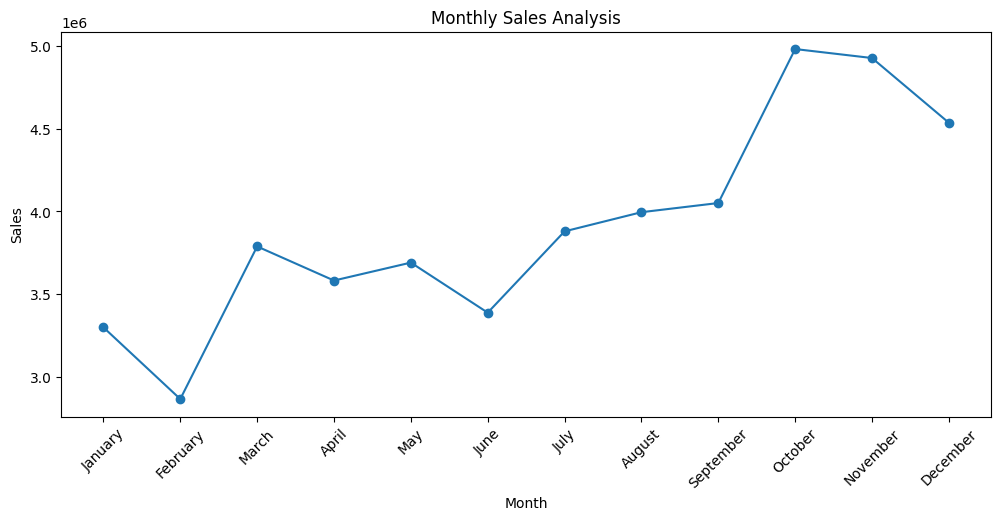

In [ ]:
monthly_sales = sales_df.groupby(
    'Month_Name'
)['Sales'].sum()

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_sales = monthly_sales.reindex(month_order)

plt.figure(figsize=(12,5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Sales Analysis')

plt.xlabel('Month')
plt.ylabel('Sales')

plt.xticks(rotation=45)

plt.show()

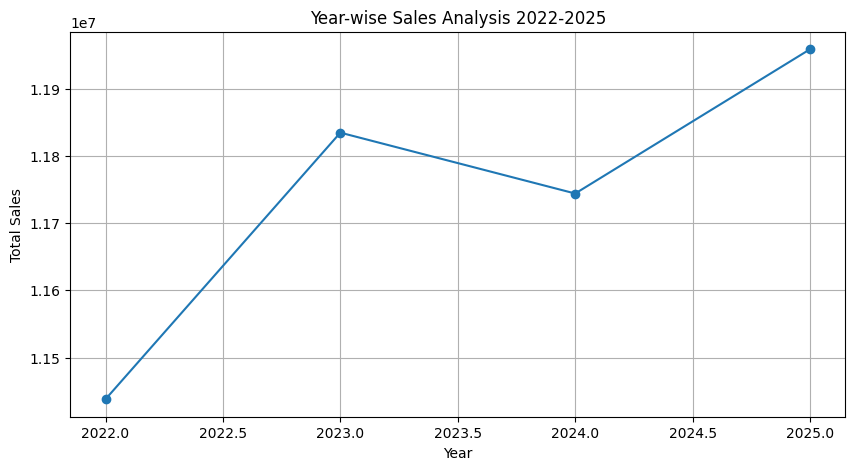

In [ ]:
year_sales = sales_df.groupby(
    'Year'
)['Sales'].sum()

plt.figure(figsize=(10,5))

plt.plot(
    year_sales.index,
    year_sales.values,
    marker='o'
)

plt.title('Year-wise Sales Analysis 2022-2025')

plt.xlabel('Year')
plt.ylabel('Total Sales')

plt.grid(True)

plt.show()

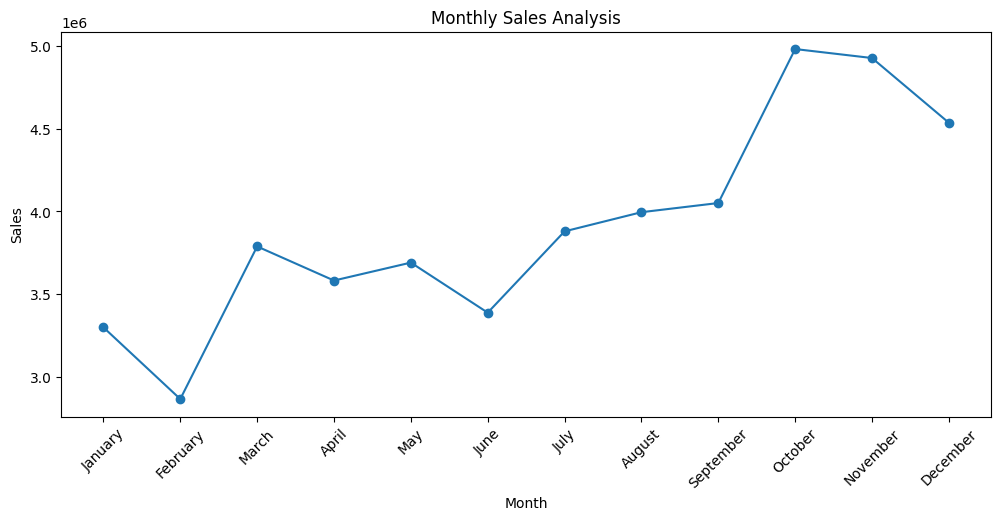

In [ ]:
monthly_sales = sales_df.groupby(
    'Month_Name'
)['Sales'].sum()

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_sales = monthly_sales.reindex(month_order)

plt.figure(figsize=(12,5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Sales Analysis')

plt.xlabel('Month')
plt.ylabel('Sales')

plt.xticks(rotation=45)

plt.show()

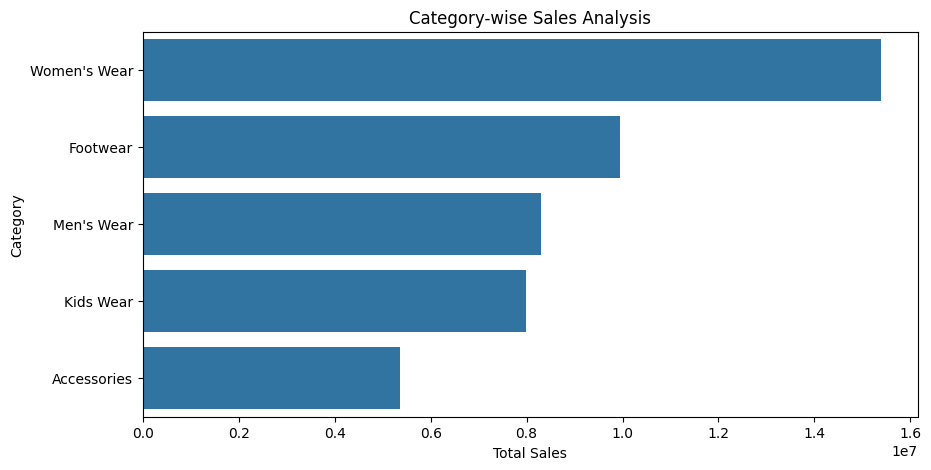

In [ ]:
category_sales = sales_df.groupby(
    'Category'
)['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))

sns.barplot(
    x=category_sales.values,
    y=category_sales.index
)

plt.title('Category-wise Sales Analysis')

plt.xlabel('Total Sales')
plt.ylabel('Category')

plt.show()

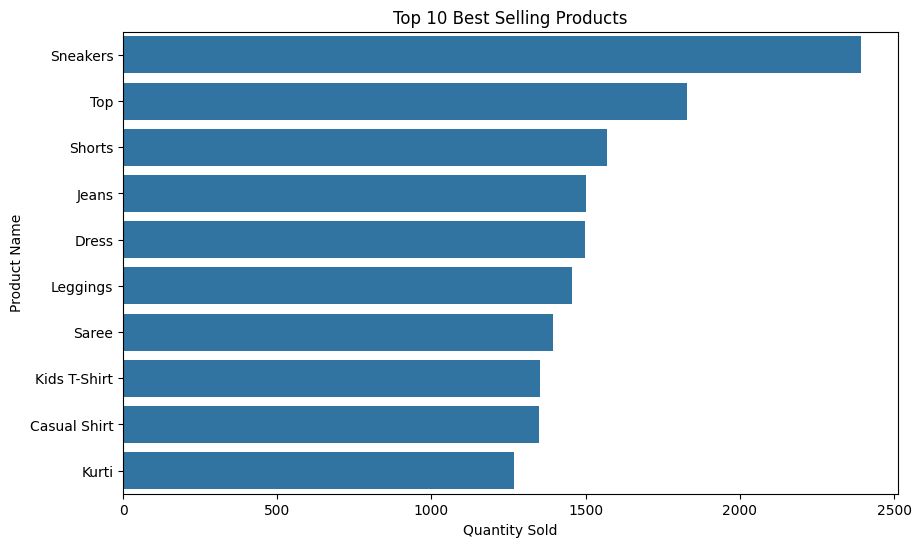

In [ ]:
top_products = sales_df.groupby(
    'Product_Name'
)['Quantity'].sum().nlargest(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title('Top 10 Best Selling Products')

plt.xlabel('Quantity Sold')
plt.ylabel('Product Name')

plt.show()

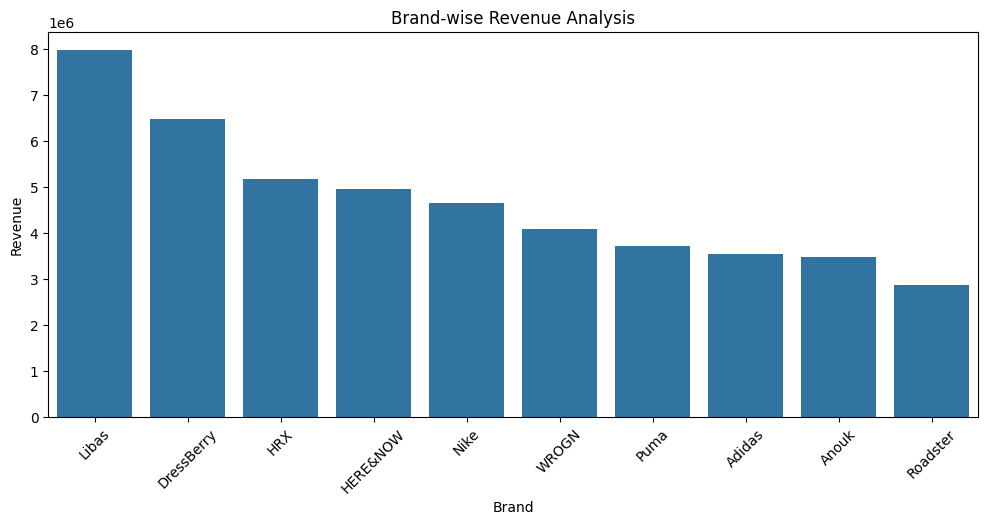

In [ ]:
brand_sales = sales_df.groupby(
    'Brand'
)['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(12,5))

sns.barplot(
    x=brand_sales.index,
    y=brand_sales.values
)

plt.title('Brand-wise Revenue Analysis')

plt.xlabel('Brand')
plt.ylabel('Revenue')

plt.xticks(rotation=45)

plt.show()

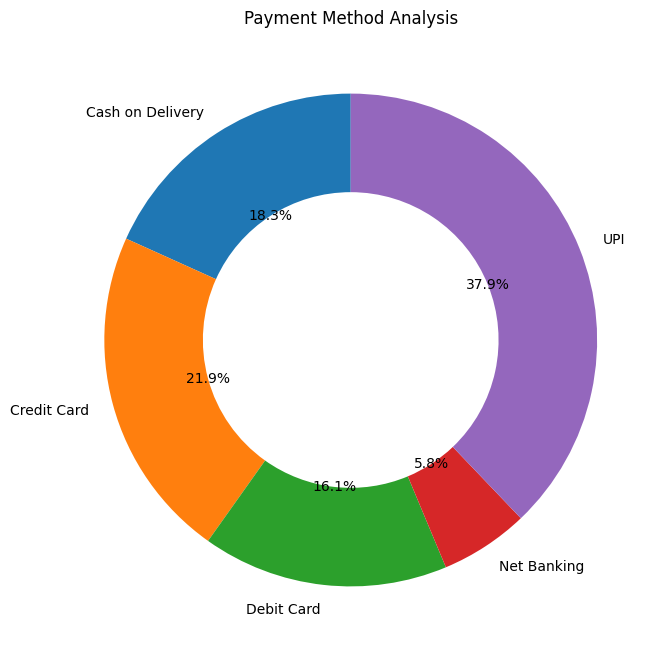

In [ ]:
payment_sales = sales_df.groupby(
    'Payment_Mode'
)['Sales'].sum()

plt.figure(figsize=(8,8))

plt.pie(
    payment_sales.values,
    labels=payment_sales.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width':0.4}
)

plt.title('Payment Method Analysis')

plt.show()

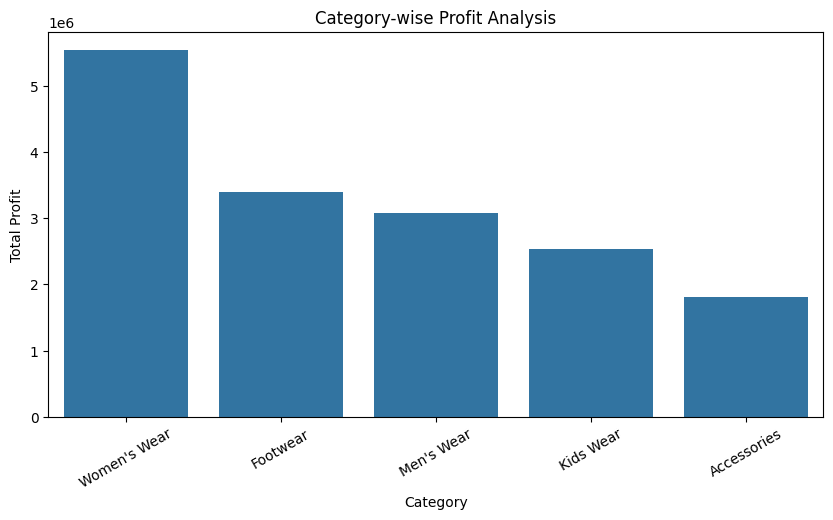

In [ ]:
category_profit = sales_df.groupby(
    'Category'
)['Profit'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))

sns.barplot(
    x=category_profit.index,
    y=category_profit.values
)

plt.title('Category-wise Profit Analysis')

plt.xlabel('Category')
plt.ylabel('Total Profit')

plt.xticks(rotation=30)

plt.show()

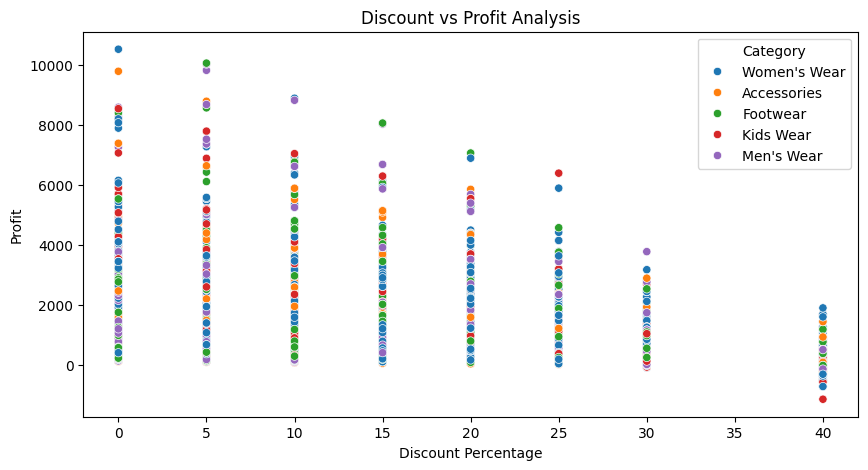

In [ ]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    data=sales_df,
    x='Discount_Percent',
    y='Profit',
    hue='Category'
)

plt.title('Discount vs Profit Analysis')

plt.xlabel('Discount Percentage')
plt.ylabel('Profit')

plt.show()

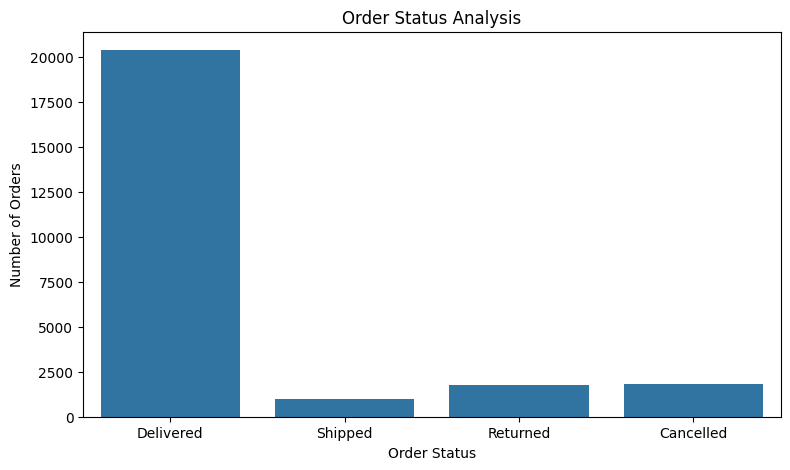

In [ ]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=df,
    x='Order_Status'
)

plt.title('Order Status Analysis')

plt.xlabel('Order Status')
plt.ylabel('Number of Orders')

plt.show()

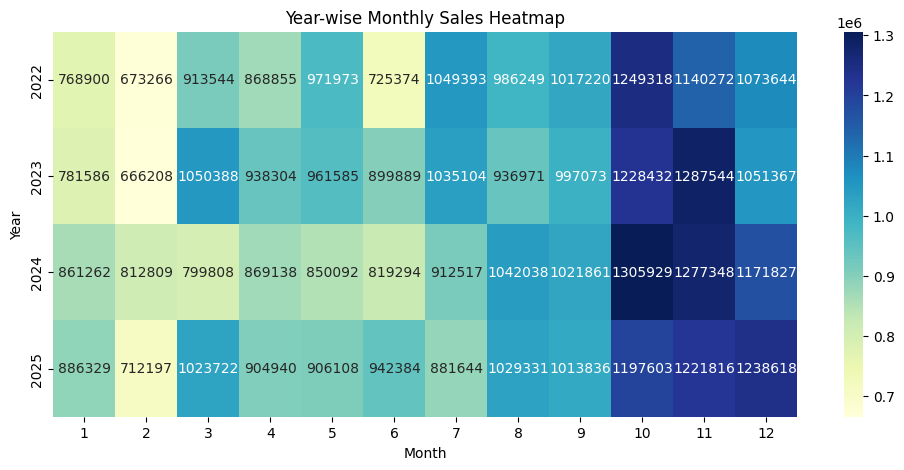

In [ ]:
pivot_data = sales_df.pivot_table(
    values='Sales',
    index='Year',
    columns='Month',
    aggfunc='sum'
)

plt.figure(figsize=(12,5))

sns.heatmap(
    pivot_data,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('Year-wise Monthly Sales Heatmap')

plt.xlabel('Month')
plt.ylabel('Year')

plt.show()

In [ ]:
customer_orders = sales_df.groupby(
    'Customer_ID'
)['Order_ID'].nunique()

repeat_customers = customer_orders[
    customer_orders > 1
]

print("Total Customers:", len(customer_orders))

print("Repeat Customers:", len(repeat_customers))

repeat_rate = (
    len(repeat_customers) / len(customer_orders)
) * 100

print("Repeat Customer Rate:", round(repeat_rate, 2), "%")

Total Customers: 4908
Repeat Customers: 4523
Repeat Customer Rate: 92.16 %


In [ ]:
city_sales = sales_df.groupby(
    'City'
)['Sales'].sum().sort_values(ascending=False)

display(city_sales)

,Sales
City,
Kochi,2897064.90
Nagpur,2837282.15
Indore,2814553.20
Bhopal,2738671.50
Jaipur,2712872.00
Mumbai,2708359.95
Bengaluru,2705473.60
Pune,2665056.40
Kolkata,2657230.55


In [ ]:
top_customers = sales_df.groupby(
    'Customer_ID'
)['Sales'].sum().nlargest(10)

display(top_customers)

,Sales
Customer_ID,
CUST04355,47908.75
CUST02924,47438.75
CUST03285,47225.05
CUST04843,45824.50
CUST03302,43202.90
CUST03979,40135.50
CUST03516,39098.15
CUST00421,37776.40
CUST03013,37168.85


In [ ]:
sales_df['Discount_Category'] = np.where(
    sales_df['Discount_Percent'] >= 20,
    'High Discount',
    'Low Discount'
)

display(
    sales_df[
        ['Product_Name', 'Discount_Percent', 'Discount_Category']
    ].head(10)
)

,Product_Name,Discount_Percent,Discount_Category
0,Dress,25.0,High Discount
1,Backpack,10.0,Low Discount
3,Sunglasses,30.0,High Discount
6,Kurti,20.0,High Discount
7,Sneakers,25.0,High Discount
8,Flats,25.0,High Discount
9,Leggings,5.0,Low Discount
10,Shorts,0.0,Low Discount
11,Leggings,15.0,Low Discount
12,Kids T-Shirt,20.0,High Discount


In [ ]:
sales_df['Sales_Category'] = np.where(
    sales_df['Sales'] >= 3000,
    'High Sales',
    'Normal Sales'
)

display(sales_df.head())

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount_Percent,Discount_Amount,Sales,Profit,...,Color,Price,Cost_Price,Age,Gender,City,State,Customer_Segment,Discount_Category,Sales_Category
0,ORD000001,2023-08-19,CUST00482,PRD0170,1,2999,25.0,749.75,2249.25,973.25,...,Pink,2999,1276,46,Female,Delhi,Delhi,Regular,High Discount,Normal Sales
1,ORD000002,2025-11-07,CUST03737,PRD0125,1,1999,10.0,199.90,1799.10,529.10,...,Yellow,1999,1270,38,Male,Ahmedabad,Gujarat,New,Low Discount,Normal Sales
3,ORD000004,2024-11-25,CUST03702,PRD0075,1,699,30.0,209.70,489.30,176.30,...,Pink,699,313,33,Female,Lucknow,Uttar Pradesh,Premium,High Discount,Normal Sales
6,ORD000007,2025-12-20,CUST01858,PRD0056,1,1999,20.0,399.80,1599.20,712.20,...,Brown,1999,887,43,Male,Ahmedabad,Gujarat,Regular,High Discount,Normal Sales
7,ORD000008,2023-11-17,CUST02811,PRD0120,2,4999,25.0,2499.50,7498.50,2286.50,...,Yellow,4999,2606,53,Female,Kochi,Kerala,Regular,High Discount,High Sales


In [ ]:
fig = px.bar(
    category_sales.reset_index(),
    x='Category',
    y='Sales',
    title='Interactive Category-wise Sales Analysis',
    color='Category'
)

fig.show()